# Predictive Maintenance for CNC Machines Using Machine Learning
## Notebook 2: Data Preprocessing Pipeline

### Purpose of Notebook 2
This notebook implements a leak-free data preprocessing pipeline for predicting CNC machine failure within the next 24 hours (`failure_within_24h`):
1. **CNC Record Filtering**: Isolates CNC equipment from multi-machine fleet data.
2. **Feature Extraction**: Extracts strictly the 5 specified sensor inputs (`vibration_rms`, `temperature_motor`, `current_phase_avg`, `pressure_level`, `rpm`) plus the binary target.
3. **Data Validation & Integrity Checks**: Verifies schema, shapes, missing rates, duplicates, and class distributions.
4. **Stratified Train-Test Splitting**: Partitions data into 80% training and 20% test sets preserving failure ratio (stratified by `y`).
5. **Leak-Free Median Imputation**: Fits `SimpleImputer(strategy='median')` strictly on `X_train` and transforms `X_test`.
6. **Feature Scaling for SVM**: Standardizes features (`StandardScaler()`) fitted strictly on training data for distance-sensitive SVM.
7. **Class Imbalance Strategy**: Documents class distribution and outlines model-level weighting strategies without synthetic oversampling.
8. **Processed Artifact Persistence**: Saves processed datasets and fitted preprocessors (`imputer.pkl`, `scaler.pkl`) for reproducible model training and deployment.


## Step 1 — Import Libraries and Environment Configuration
We load data processing, scikit-learn preprocessing utilities, and persistence libraries.


In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Visual styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Create output directories if they do not exist
os.makedirs('../dataset/processed', exist_ok=True)
os.makedirs('../images/preprocessing', exist_ok=True)
os.makedirs('../models', exist_ok=True)

print("Preprocessing libraries imported and output directories confirmed.")


Preprocessing libraries imported and output directories confirmed.


## Step 2 — Load Original Dataset and Filter CNC Records
We load the raw CSV file using relative path `../dataset/raw/predictive_maintenance_v3.csv` and filter strictly for CNC machine records (`df["machine_type"] == "CNC"`).


In [2]:
# Load raw dataset
RAW_PATH = "../dataset/raw/predictive_maintenance_v3.csv"
df_raw = pd.read_csv(RAW_PATH)
print(f"Raw dataset loaded. Total rows across all machines: {df_raw.shape[0]:,}, Total columns: {df_raw.shape[1]}")

# Filter strictly for CNC machine records
df_cnc = df_raw[df_raw["machine_type"] == "CNC"].copy()
print(f"Filtered CNC records: {len(df_cnc):,} rows ({len(df_cnc)/len(df_raw)*100:.2f}% of raw fleet data)")


Raw dataset loaded. Total rows across all machines: 24,042, Total columns: 15
Filtered CNC records: 5,937 rows (24.69% of raw fleet data)


## Step 3 — Extract ONLY Required Columns
In strict accordance with project specifications, we retain **only** the 5 operational sensor features and the binary target:
- Features: `vibration_rms`, `temperature_motor`, `current_phase_avg`, `pressure_level`, `rpm`
- Target: `failure_within_24h`

All extraneous columns (`machine_type`, `machine_id`, `timestamp`, `product_type`, `failure_type`, `rul_hours`, `estimated_repair_cost`, etc.) are removed.


In [3]:
FEATURES = [
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm"
]

TARGET = "failure_within_24h"

selected_columns = FEATURES + [TARGET]

# Extract strictly selected columns
df_model = df_cnc[selected_columns].copy()

# Save the filtered selected features dataset
PROCESSED_DATA_PATH = "../dataset/processed/cnc_selected_features.csv"
df_model.to_csv(PROCESSED_DATA_PATH, index=False)
print(f"Extracted {len(selected_columns)} columns ({len(FEATURES)} features + 1 target).")
print(f"Saved selected CNC dataset to: {PROCESSED_DATA_PATH}")
print(f"Shape: {df_model.shape[0]} rows x {df_model.shape[1]} columns")
df_model.head()


Extracted 6 columns (5 features + 1 target).
Saved selected CNC dataset to: ../dataset/processed/cnc_selected_features.csv
Shape: 5937 rows x 6 columns


,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,failure_within_24h
0,0.81,49.51,5.10,23.6,860.9,0
1,0.75,40.58,5.30,23.6,899.6,0
2,0.71,49.70,NaN,21.3,862.7,0
3,0.76,43.04,4.79,22.6,870.4,0
4,0.88,41.39,4.44,22.2,881.9,0


## Step 4 — Data Validation & Integrity Checks
We rigorously check:
- Dataset dimensions
- Data types of all 6 columns
- Missing values count and percentage
- Duplicate rows
- Target values and distribution


In [4]:
# 1. Dimensions check
print(f"1. Dataset Shape: {df_model.shape[0]} rows, {df_model.shape[1]} columns")

# 2. Data types check
print("\n2. Data Types and Non-Null Overview:")
validation_dtypes = pd.DataFrame({
    'Column': df_model.columns,
    'Data Type': df_model.dtypes.values,
    'Non-Null Count': df_model.notnull().sum().values,
    'Null Count': df_model.isnull().sum().values,
    'Null %': (df_model.isnull().sum() / len(df_model) * 100).round(2).values
})
display(validation_dtypes)

# 3. Duplicate check
duplicate_count = df_model.duplicated().sum()
print(f"\n3. Duplicate Rows Count: {duplicate_count}")
if duplicate_count == 0:
    print("   -> No duplicate records exist in the model dataset.")
else:
    print(f"   -> Found {duplicate_count} duplicates; handling required.")

# 4. Target validity check
unique_targets = df_model[TARGET].unique()
print(f"\n4. Unique Target Values: {sorted(unique_targets)}")
assert set(unique_targets).issubset({0, 1}), "Error: Target contains values outside {0, 1}!"
print("   -> Target is strictly binary {0, 1}.")

# 5. Target distribution check
target_dist = df_model[TARGET].value_counts().sort_index()
target_dist_pct = (df_model[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)
dist_df = pd.DataFrame({
    'Class': ['0 (Normal Operation)', '1 (Failure within 24h)'],
    'Count': target_dist.values,
    'Percentage (%)': target_dist_pct.values
})
print("\n5. Target Distribution:")
display(dist_df)


1. Dataset Shape: 5937 rows, 6 columns

2. Data Types and Non-Null Overview:


,Column,Data Type,Non-Null Count,Null Count,Null %
0,vibration_rms,float64,5697,240,4.04
1,temperature_motor,float64,5748,189,3.18
2,current_phase_avg,float64,5783,154,2.59
3,pressure_level,float64,5725,212,3.57
4,rpm,float64,5813,124,2.09
5,failure_within_24h,int64,5937,0,0.00



3. Duplicate Rows Count: 0
   -> No duplicate records exist in the model dataset.

4. Unique Target Values: [np.int64(0), np.int64(1)]
   -> Target is strictly binary {0, 1}.

5. Target Distribution:


,Class,Count,Percentage (%)
0,0 (Normal Operation),5103,85.95
1,1 (Failure within 24h),834,14.05


## Step 5 — Stratified Train-Test Split (80% Train, 20% Test)
To evaluate model generalization fairly:
- Training set: 80% (approx. 4,749 samples)
- Test set: 20% (approx. 1,188 samples)
- `random_state = 42` for exact reproducibility
- `stratify = y` to preserve the exact 14.05% failure ratio across train and test partitions

**Crucial Leakage Rule:**
Train-test splitting occurs **before** any imputation or scaling. Imputers and scalers must be fitted **only** on the training partition.


In [5]:
# Separate feature matrix X and target vector y
X = df_model[FEATURES]
y = df_model[TARGET]

# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test Shape : {X_test.shape}  | y_test Shape : {y_test.shape}")

train_fail_rate = (y_train.sum() / len(y_train)) * 100
test_fail_rate = (y_test.sum() / len(y_test)) * 100

split_summary = pd.DataFrame({
    'Partition': ['Training Set (80%)', 'Test Set (20%)', 'Total CNC'],
    'Total Samples': [len(y_train), len(y_test), len(df_model)],
    'Normal (Class 0)': [(y_train == 0).sum(), (y_test == 0).sum(), (df_model[TARGET] == 0).sum()],
    'Failure (Class 1)': [(y_train == 1).sum(), (y_test == 1).sum(), (df_model[TARGET] == 1).sum()],
    'Failure Rate (%)': [round(train_fail_rate, 2), round(test_fail_rate, 2), round((df_model[TARGET] == 1).mean() * 100, 2)]
})
print("\nTrain/Test Partition Summary:")
display(split_summary)


X_train Shape: (4749, 5) | y_train Shape: (4749,)
X_test Shape : (1188, 5)  | y_test Shape : (1188,)

Train/Test Partition Summary:


,Partition,Total Samples,Normal (Class 0),Failure (Class 1),Failure Rate (%)
0,Training Set (80%),4749,4082,667,14.05
1,Test Set (20%),1188,1021,167,14.06
2,Total CNC,5937,5103,834,14.05


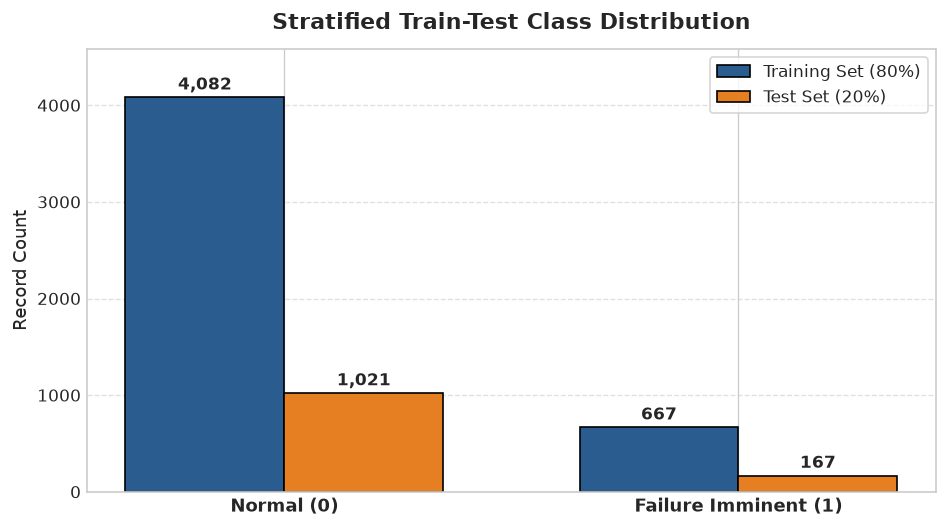

In [6]:
# Visualize stratified split distribution
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_width = 0.35
x_pos = np.arange(2)

train_counts = [(y_train == 0).sum(), (y_train == 1).sum()]
test_counts = [(y_test == 0).sum(), (y_test == 1).sum()]

b1 = ax.bar(x_pos - bar_width/2, train_counts, bar_width, label='Training Set (80%)', color='#2b5c8f', edgecolor='black')
b2 = ax.bar(x_pos + bar_width/2, test_counts, bar_width, label='Test Set (20%)', color='#e67e22', edgecolor='black')

for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 40, f'{h:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(x_pos)
ax.set_xticklabels(['Normal (0)', 'Failure Imminent (1)'], fontsize=11, fontweight='bold')
ax.set_ylabel('Record Count', fontsize=11)
ax.set_title('Stratified Train-Test Class Distribution', fontsize=13, fontweight='bold', pad=12)
ax.set_ylim(0, max(train_counts) + 500)
ax.legend(frameon=True, fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../images/preprocessing/train_test_split_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 6 — Missing Value Handling via Leak-Free Median Imputation
Industrial sensor readings contain occasional dropouts due to communication latency or sensor recalibration.
- We use `SimpleImputer(strategy='median')`.
- **Median** is chosen over mean because it is robust to extreme sensor spikes (which occur during abnormal machining loads).
- **Leakage Prevention**: We fit the imputer **strictly** on `X_train`:
  ```python
  imputer.fit(X_train)
  X_train_imputed = imputer.transform(X_train)
  X_test_imputed = imputer.transform(X_test)
  ```
  The test set medians are never used during imputation.


In [7]:
# Instantiate SimpleImputer with median strategy
imputer = SimpleImputer(strategy="median")

# Fit strictly on X_train and transform both partitions
X_train_imputed_arr = imputer.fit_transform(X_train)
X_test_imputed_arr = imputer.transform(X_test)

# Convert back to pandas DataFrame with consistent column names and indices
X_train_imputed = pd.DataFrame(X_train_imputed_arr, columns=FEATURES, index=X_train.index)
X_test_imputed = pd.DataFrame(X_test_imputed_arr, columns=FEATURES, index=X_test.index)

# Display fitted training medians
imputer_medians = pd.DataFrame({
    'Feature': FEATURES,
    'Fitted Training Median': imputer.statistics_,
    'Train Nulls Before': X_train.isnull().sum().values,
    'Train Nulls After': X_train_imputed.isnull().sum().values,
    'Test Nulls Before': X_test.isnull().sum().values,
    'Test Nulls After': X_test_imputed.isnull().sum().values
})
print("Fitted Median Imputation Statistics:")
display(imputer_medians)

# Verification assertion
assert X_train_imputed.isnull().sum().sum() == 0, "Error: Missing values remain in training set!"
assert X_test_imputed.isnull().sum().sum() == 0, "Error: Missing values remain in test set!"
print("Verification Success: Zero missing values remaining in train and test feature sets.")


Fitted Median Imputation Statistics:


,Feature,Fitted Training Median,Train Nulls Before,Train Nulls After,Test Nulls Before,Test Nulls After
0,vibration_rms,1.980,194,0,46,0
1,temperature_motor,53.795,141,0,48,0
2,current_phase_avg,10.180,119,0,35,0
3,pressure_level,55.400,172,0,40,0
4,rpm,2756.150,97,0,27,0


Verification Success: Zero missing values remaining in train and test feature sets.


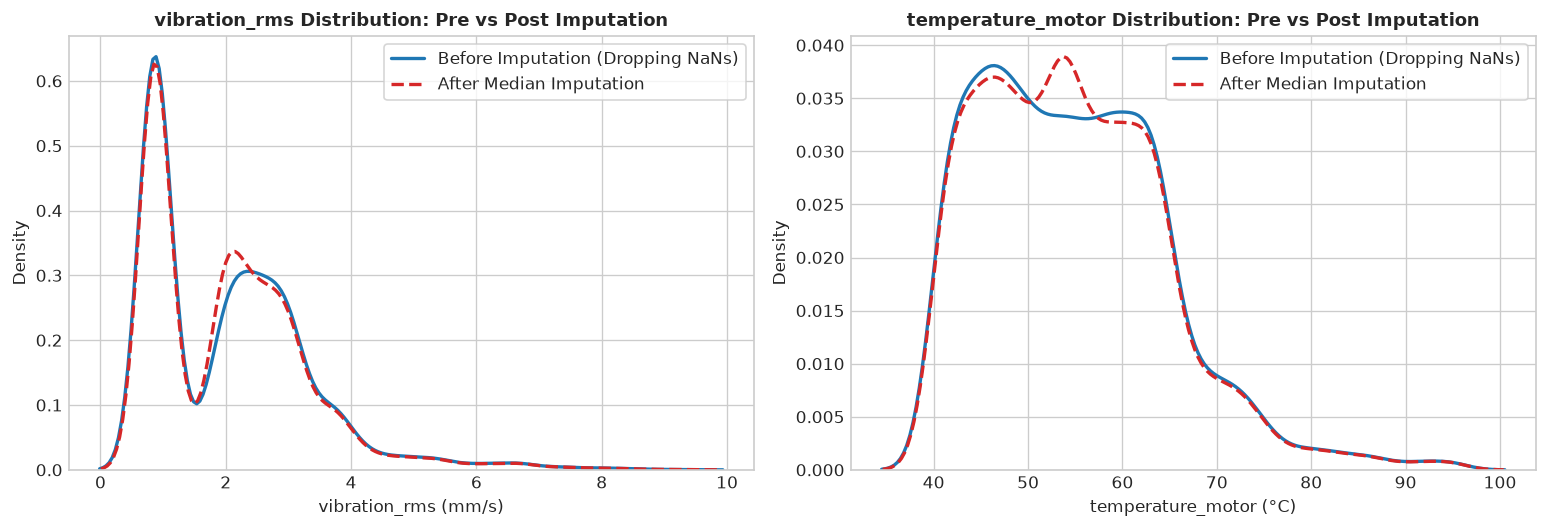

In [8]:
# Visualize feature distributions before and after imputation on training data
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.kdeplot(X_train['vibration_rms'].dropna(), ax=axes[0], label='Before Imputation (Dropping NaNs)', color='#1f77b4', linewidth=2)
sns.kdeplot(X_train_imputed['vibration_rms'], ax=axes[0], label='After Median Imputation', color='#d62728', linestyle='--', linewidth=2)
axes[0].set_title('vibration_rms Distribution: Pre vs Post Imputation', fontsize=11, fontweight='bold')
axes[0].set_xlabel('vibration_rms (mm/s)', fontsize=10)
axes[0].legend(frameon=True)

sns.kdeplot(X_train['temperature_motor'].dropna(), ax=axes[1], label='Before Imputation (Dropping NaNs)', color='#1f77b4', linewidth=2)
sns.kdeplot(X_train_imputed['temperature_motor'], ax=axes[1], label='After Median Imputation', color='#d62728', linestyle='--', linewidth=2)
axes[1].set_title('temperature_motor Distribution: Pre vs Post Imputation', fontsize=11, fontweight='bold')
axes[1].set_xlabel('temperature_motor (°C)', fontsize=10)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig('../images/preprocessing/imputation_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 7 — Feature Scaling (StandardScaler for SVM)
Different machine learning algorithms have distinct mathematical requirements:
1. **Support Vector Machines (SVM)** compute geometric distances using a Radial Basis Function (RBF) kernel. Variables with large ranges (e.g. `rpm` ~ 800–1200) would completely dominate variables with small ranges (e.g. `vibration_rms` ~ 0.5–2.0). Hence, **SVM requires standardized features** ($\mu = 0, \sigma = 1$).
2. **Random Forest** and **XGBoost** are decision-tree ensembles. They split features monotonically based on threshold inequalities ($x_i \le 	heta$). Scaling does not change threshold ordering, so tree models do **not** require scaling.

**Leakage Prevention:**
The `StandardScaler` is fitted **strictly** on `X_train_imputed` and applied to `X_test_imputed`.


In [9]:
# Instantiate StandardScaler
scaler = StandardScaler()

# Fit strictly on imputed training features and transform both sets
X_train_scaled_arr = scaler.fit_transform(X_train_imputed)
X_test_scaled_arr = scaler.transform(X_test_imputed)

# Convert to pandas DataFrames
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=FEATURES, index=X_test.index)

# Summary of scaling parameters
scaling_stats = pd.DataFrame({
    'Feature': FEATURES,
    'Fitted Mean (mu)': scaler.mean_.round(3),
    'Fitted Std (sigma)': np.sqrt(scaler.var_).round(3),
    'Scaled Train Mean': X_train_scaled.mean().round(4).values,
    'Scaled Train Std': X_train_scaled.std(ddof=0).round(4).values
})
print("Fitted StandardScaler Parameters:")
display(scaling_stats)


Fitted StandardScaler Parameters:


,Feature,Fitted Mean (mu),Fitted Std (sigma),Scaled Train Mean,Scaled Train Std
0,vibration_rms,2.042,1.255,0.0,1.0
1,temperature_motor,54.711,9.778,-0.0,1.0
2,current_phase_avg,10.154,5.680,0.0,1.0
3,pressure_level,51.258,27.605,-0.0,1.0
4,rpm,2055.771,1094.725,-0.0,1.0


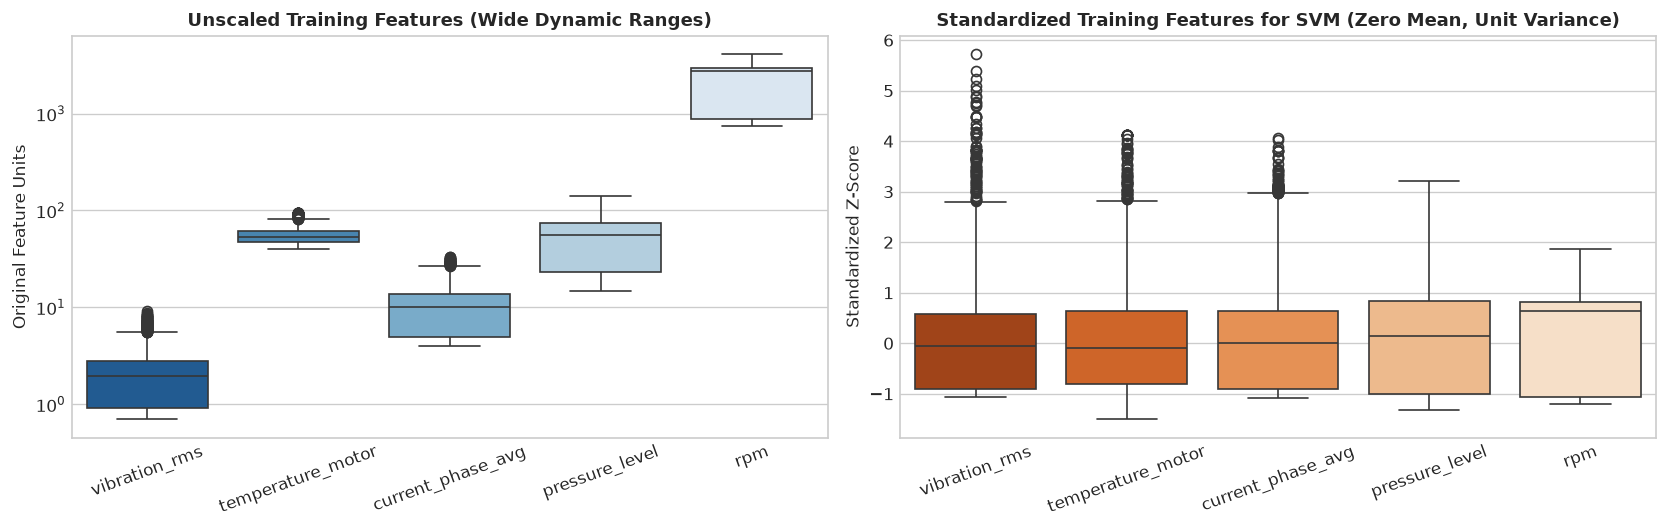

In [10]:
# Compare unscaled vs scaled distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=X_train_imputed, ax=axes[0], palette='Blues_r')
axes[0].set_title('Unscaled Training Features (Wide Dynamic Ranges)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Original Feature Units', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_yscale('log')

sns.boxplot(data=X_train_scaled, ax=axes[1], palette='Oranges_r')
axes[1].set_title('Standardized Training Features for SVM (Zero Mean, Unit Variance)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Standardized Z-Score', fontsize=10)
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('../images/preprocessing/feature_scaling_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 8 — Class Imbalance Strategy
The CNC dataset contains **14.05% failure cases** (approx. 6:1 normal to failure ratio).

### Handling Methodology:
1. **No Synthetic Oversampling Initially**: We do **not** use SMOTE or random oversampling initially. SMOTE creates synthetic points by linear interpolation in feature space, which can introduce artificial sensor combinations uncharacteristic of physical machine dynamics.
2. **Original Distribution Baseline**: We first train and evaluate all three models using the natural physical distribution.
3. **Class Weight Investigation**: In Notebook 3, we investigate cost-sensitive algorithmic adjustment (`class_weight='balanced'`) for Random Forest and SVM. This penalizes false negatives proportionally without corrupting feature distributions.


In [11]:
# Document class imbalance parameters
n_samples = len(y_train)
n_classes = 2
n_normal = (y_train == 0).sum()
n_failure = (y_train == 1).sum()

weight_normal = n_samples / (n_classes * n_normal)
weight_failure = n_samples / (n_classes * n_failure)

print("Class Imbalance Analytical Profile (Training Set):")
print(f"  • Total Training Observations : {n_samples:,}")
print(f"  • Normal (Class 0) Count      : {n_normal:,} ({n_normal/n_samples*100:.2f}%)")
print(f"  • Failure (Class 1) Count     : {n_failure:,} ({n_failure/n_samples*100:.2f}%)")
print(f"  • Theoretical Balanced Weight (Class 0): {weight_normal:.4f}")
print(f"  • Theoretical Balanced Weight (Class 1): {weight_failure:.4f}")
print(f"  • Weight Multiplier on Failure Errors  : {weight_failure / weight_normal:.2f}x")


Class Imbalance Analytical Profile (Training Set):
  • Total Training Observations : 4,749
  • Normal (Class 0) Count      : 4,082 (85.95%)
  • Failure (Class 1) Count     : 667 (14.05%)
  • Theoretical Balanced Weight (Class 0): 0.5817
  • Theoretical Balanced Weight (Class 1): 3.5600
  • Weight Multiplier on Failure Errors  : 6.12x


## Step 9 — Save Processed Datasets and Preprocessor Artifacts
We save all processed splits and preprocessor objects so that Notebook 3 (and downstream production scripts) can load the exact identical data partitions.


In [12]:
# Save processed feature matrices and target vectors
X_train_imputed.to_csv("../dataset/processed/X_train.csv", index=False)
X_test_imputed.to_csv("../dataset/processed/X_test.csv", index=False)

X_train_scaled.to_csv("../dataset/processed/X_train_scaled.csv", index=False)
X_test_scaled.to_csv("../dataset/processed/X_test_scaled.csv", index=False)

y_train.to_csv("../dataset/processed/y_train.csv", index=False)
y_test.to_csv("../dataset/processed/y_test.csv", index=False)

# Save imputer and scaler models for future inference
joblib.dump(imputer, "../models/imputer.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

print("Saved Processed Datasets to ../dataset/processed/:")
print("  ✓ cnc_selected_features.csv (5,937 x 6)")
print("  ✓ X_train.csv               (4,749 x 5 - Imputed)")
print("  ✓ X_test.csv                (1,188 x 5 - Imputed)")
print("  ✓ X_train_scaled.csv        (4,749 x 5 - Scaled for SVM)")
print("  ✓ X_test_scaled.csv         (1,188 x 5 - Scaled for SVM)")
print("  ✓ y_train.csv               (4,749 x 1)")
print("  ✓ y_test.csv                (1,188 x 1)")
print("\nSaved Preprocessors to ../models/:")
print("  ✓ imputer.pkl")
print("  ✓ scaler.pkl")
print("\nPreprocessing pipeline completed successfully! Proceed to Notebook 03.")


Saved Processed Datasets to ../dataset/processed/:
  ✓ cnc_selected_features.csv (5,937 x 6)
  ✓ X_train.csv               (4,749 x 5 - Imputed)
  ✓ X_test.csv                (1,188 x 5 - Imputed)
  ✓ X_train_scaled.csv        (4,749 x 5 - Scaled for SVM)
  ✓ X_test_scaled.csv         (1,188 x 5 - Scaled for SVM)
  ✓ y_train.csv               (4,749 x 1)
  ✓ y_test.csv                (1,188 x 1)

Saved Preprocessors to ../models/:
  ✓ imputer.pkl
  ✓ scaler.pkl

Preprocessing pipeline completed successfully! Proceed to Notebook 03.
